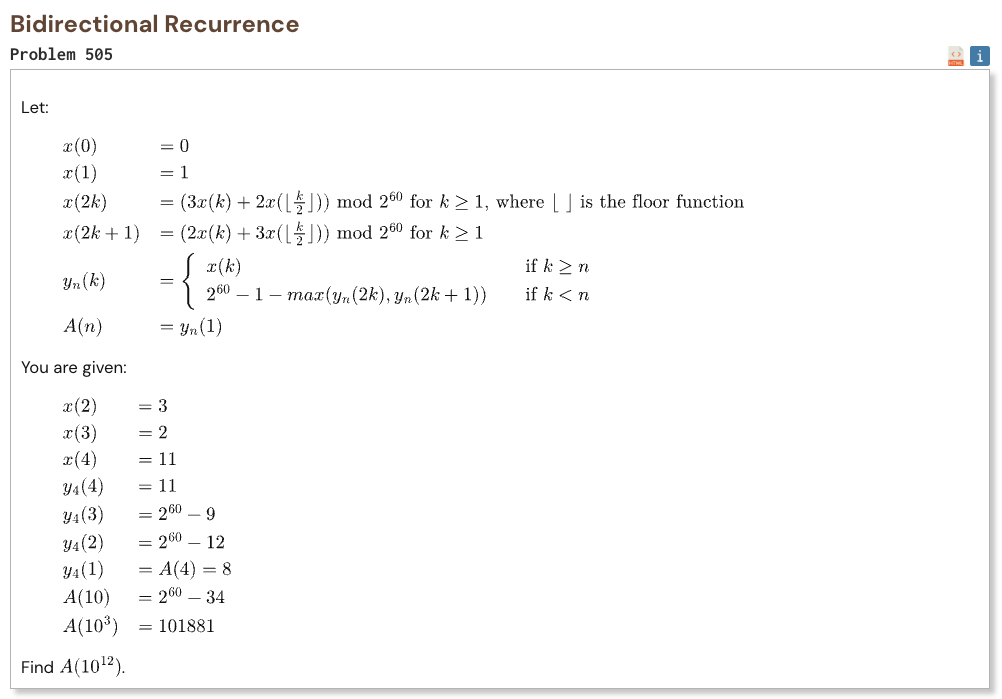

## Initial approach

- evaluate the recurrence as a binary game tree
- keep the current value and its parent while moving down the tree
- alternate the value transformation automatically through the recursive calls
- use alpha beta pruning to skip branches that cannot change the final result
- the tree depth is only about forty even for the huge target
- use numba to JIT compile the recursion because pure Python is too slow here
- calculate the value directly for the target size

In [1]:
%%time

from numba import njit

N = 10**12
MASK = (1 << 60) - 1

@njit
def solve(k, parent, current, alpha, beta):
    if k >= N:
        return current

    left = solve(
        2 * k,
        current,
        (2 * parent + 3 * current) & MASK,
        MASK - beta,
        MASK - alpha
    )

    if MASK - left <= alpha:
        return alpha

    right = solve(
        2 * k + 1,
        current,
        (3 * parent + 2 * current) & MASK,
        left,
        MASK - alpha
    )

    return MASK - max(left, right)

result = solve(1, 0, 1, 0, MASK)

print("Result:", result)

Result: 714591308667615832
CPU times: user 6.19 s, sys: 109 ms, total: 6.3 s
Wall time: 7.76 s
